<a href="https://colab.research.google.com/github/192472117simats-hue/CSA1615-Data-WareHouse-and-Data-Mining/blob/main/Copy_of_Customer_Lifetime_Value_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Customer Lifetime Value Prediction")
print("Libraries imported successfully!")

Customer Lifetime Value Prediction
Libraries imported successfully!


In [ ]:
file_path = '/content/sample_data/Online Retail.xlsx'

df = pd.read_excel(file_path)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

FileNotFoundError: [Errno 2] No such file or directory: '/content/sample_data/Online Retail.xlsx'

In [ ]:
import os

for root, dirs, files in os.walk('/content'):
    for file in files:
        if file.endswith(('.xlsx', '.xls')):
            print(os.path.join(root, file))

/content/Online Retail.xlsx


In [ ]:
df = pd.read_excel('/content/Online Retail.xlsx')

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [ ]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

print("\nDataset Information:")
df.info()

Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Duplicate Records:
5268

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [ ]:
# Remove missing values
df = df.dropna(subset=['CustomerID', 'Description'])

# Remove duplicate records
df = df.drop_duplicates()

# Remove invalid transactions
df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]

# Reset index
df = df.reset_index(drop=True)

print("Data Cleaning Completed!")
print("Remaining Records:", len(df))
print("Missing Values:\n", df.isnull().sum().sum())
print("Duplicate Records:", df.duplicated().sum())

Data Cleaning Completed!
Remaining Records: 392692
Missing Values:
 0
Duplicate Records: 0


In [ ]:
# Calculate total transaction amount
df['TotalAmount'] = df['Quantity'] * df['UnitPrice']

# Display transformed dataset
print("Data Transformation Completed!")

df[['CustomerID', 'Quantity', 'UnitPrice', 'TotalAmount']].head(10)


Data Transformation Completed!


,CustomerID,Quantity,UnitPrice,TotalAmount
0,17850.0,6,2.55,15.30
1,17850.0,6,3.39,20.34
2,17850.0,8,2.75,22.00
3,17850.0,6,3.39,20.34
4,17850.0,6,3.39,20.34
5,17850.0,2,7.65,15.30
6,17850.0,6,4.25,25.50
7,17850.0,6,1.85,11.10
8,17850.0,6,1.85,11.10
9,13047.0,32,1.69,54.08


In [ ]:
# Create customer-level features
customer_data = df.groupby('CustomerID').agg({
    'InvoiceNo': 'nunique',
    'Quantity': 'sum',
    'TotalAmount': 'sum'
}).reset_index()

# Rename columns
customer_data.columns = [
    'CustomerID',
    'PurchaseFrequency',
    'TotalQuantity',
    'TotalSpending'
]

print("Feature Selection Completed!")
print("Total Customers:", len(customer_data))

customer_data.head()

Feature Selection Completed!
Total Customers: 4338


,CustomerID,PurchaseFrequency,TotalQuantity,TotalSpending
0,12346.0,1,74215,77183.60
1,12347.0,7,2458,4310.00
2,12348.0,4,2341,1797.24
3,12349.0,1,631,1757.55
4,12350.0,1,197,334.40


In [ ]:
# Create CLV target
customer_data['CLV'] = (
    customer_data['TotalSpending'] *
    customer_data['PurchaseFrequency']
)

print("CLV Target Created Successfully!")

customer_data.head()

CLV Target Created Successfully!


,CustomerID,PurchaseFrequency,TotalQuantity,TotalSpending,CLV
0,12346.0,1,74215,77183.60,77183.60
1,12347.0,7,2458,4310.00,30170.00
2,12348.0,4,2341,1797.24,7188.96
3,12349.0,1,631,1757.55,1757.55
4,12350.0,1,197,334.40,334.40


In [ ]:
# Set the date for separating past and future transactions
cutoff_date = '2011-09-01'

# Historical customer features
past_data = df[df['InvoiceDate'] < cutoff_date]

X = past_data.groupby('CustomerID').agg({
    'InvoiceNo': 'nunique',
    'Quantity': 'sum',
    'TotalAmount': 'sum'
}).reset_index()

X.columns = [
    'CustomerID',
    'PurchaseFrequency',
    'TotalQuantity',
    'TotalSpending'
]

# Future customer spending (target)
future_data = df[df['InvoiceDate'] >= cutoff_date]

y = future_data.groupby('CustomerID')['TotalAmount'].sum().reset_index()
y.columns = ['CustomerID', 'FutureSpending']

# Combine historical features and future spending
model_data = X.merge(y, on='CustomerID', how='left')
model_data['FutureSpending'] = model_data['FutureSpending'].fillna(0)

print("Prediction Dataset Prepared!")
print("Total Customers:", len(model_data))

model_data.head()


Prediction Dataset Prepared!
Total Customers: 3317


,CustomerID,PurchaseFrequency,TotalQuantity,TotalSpending,FutureSpending
0,12346.0,1,74215,77183.60,0.00
1,12347.0,5,1590,2790.86,1519.14
2,12348.0,3,2124,1487.24,310.00
3,12350.0,1,197,334.40,0.00
4,12352.0,5,254,1561.81,944.23


In [ ]:
from sklearn.model_selection import train_test_split

# Input features
X = model_data[
    ['PurchaseFrequency', 'TotalQuantity', 'TotalSpending']
]

# Target value
y = model_data['FutureSpending']

# Split dataset into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training and Testing Data Prepared!")
print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

Training and Testing Data Prepared!
Training Records: 2653
Testing Records: 664


In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Create Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

# Train the model
rf_model.fit(X_train, y_train)

# Make predictions
rf_predictions = rf_model.predict(X_test)

# Evaluate the model
rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))
rf_r2 = r2_score(y_test, rf_predictions)

print("Random Forest Model Trained Successfully!")
print("MAE:", round(rf_mae, 2))
print("RMSE:", round(rf_rmse, 2))
print("R2 Score:", round(rf_r2, 4))

Random Forest Model Trained Successfully!
MAE: 997.26
RMSE: 5057.74
R2 Score: 0.4435


In [ ]:
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Create Neural Network model
nn_model = make_pipeline(
    StandardScaler(),
    MLPRegressor(
        hidden_layer_sizes=(64, 32),
        max_iter=500,
        random_state=42,
        early_stopping=True
    )
)

# Train the model
nn_model.fit(X_train, y_train)

# Make predictions
nn_predictions = nn_model.predict(X_test)

# Evaluate the model
nn_mae = mean_absolute_error(y_test, nn_predictions)
nn_rmse = np.sqrt(mean_squared_error(y_test, nn_predictions))
nn_r2 = r2_score(y_test, nn_predictions)

print("Neural Network Model Trained Successfully!")
print("MAE:", round(nn_mae, 2))
print("RMSE:", round(nn_rmse, 2))
print("R2 Score:", round(nn_r2, 4))

Neural Network Model Trained Successfully!
MAE: 1002.73
RMSE: 5694.31
R2 Score: 0.2945


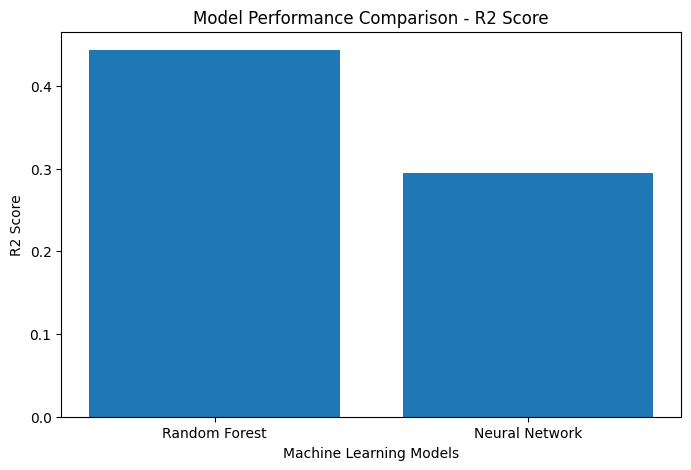

In [ ]:
models = ['Random Forest', 'Neural Network']
mae_scores = [rf_mae, nn_mae]
rmse_scores = [rf_rmse, nn_rmse]
r2_scores = [rf_r2, nn_r2]

plt.figure(figsize=(8, 5))
plt.bar(models, r2_scores)
plt.title('Model Performance Comparison - R2 Score')
plt.ylabel('R2 Score')
plt.xlabel('Machine Learning Models')
plt.show()

In [ ]:
# Add predicted spending to customer data
model_data['PredictedCLV'] = rf_model.predict(X)

# Divide customers into three segments
model_data['CustomerSegment'] = pd.qcut(
    model_data['PredictedCLV'],
    q=3,
    labels=['Low Value', 'Medium Value', 'High Value']
)

print("Customer Segmentation Completed!")
print(model_data['CustomerSegment'].value_counts())

model_data.head(10)

Customer Segmentation Completed!
CustomerSegment
Low Value       1106
High Value      1106
Medium Value    1105
Name: count, dtype: int64


,CustomerID,PurchaseFrequency,TotalQuantity,TotalSpending,FutureSpending,PredictedCLV,CustomerSegment
0,12346.0,1,74215,77183.60,0.00,43383.0487,High Value
1,12347.0,5,1590,2790.86,1519.14,1387.3007,High Value
2,12348.0,3,2124,1487.24,310.00,502.2116,Medium Value
3,12350.0,1,197,334.40,0.00,31.6858,Low Value
4,12352.0,5,254,1561.81,944.23,864.6326,High Value
5,12353.0,1,20,89.00,0.00,40.6390,Low Value
6,12354.0,1,530,1079.40,0.00,114.7163,Low Value
7,12355.0,1,240,459.40,0.00,115.8654,Low Value
8,12356.0,2,1586,2753.08,58.35,191.7200,Medium Value
9,12358.0,1,100,484.86,683.20,685.8286,High Value


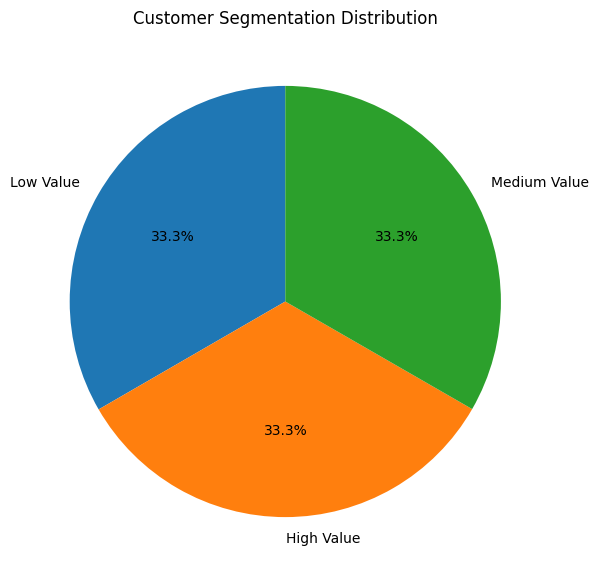

In [ ]:
segment_counts = model_data['CustomerSegment'].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    segment_counts,
    labels=segment_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Customer Segmentation Distribution')
plt.show()